In [2]:
import pydantic
print(pydantic.__version__)

2.12.5


In [3]:
from pydantic import BaseModel, Field, ValidationError

In [4]:
class ProductInput(BaseModel):
    name: str
    price: float = Field(gt=0)

In [19]:
class ProductInput(BaseModel):
    model_config = {"str_strip_whitespace": True}
    name: str = Field(min_length=1)
    price: float = Field(gt=0)
    category: str = Field(min_length=1)
    image_path: str = Field(min_length=1)

In [20]:
try:
    test_product = ProductInput(name=" ", price=19.99)
    print("Valid product:", test_product)
except ValidationError as error:
    print(error)

3 validation errors for ProductInput
name
  String should have at least 1 character [type=string_too_short, input_value=' ', input_type=str]
    For further information visit https://errors.pydantic.dev/2.12/v/string_too_short
category
  Field required [type=missing, input_value={'name': ' ', 'price': 19.99}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.12/v/missing
image_path
  Field required [type=missing, input_value={'name': ' ', 'price': 19.99}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.12/v/missing


In [21]:
test_product = ProductInput(
    name="Puma T-shirt",
    price=19.99,
    category="Apparel",
    image_path="product_images/product_4.png"
)
print(test_product)

name='Puma T-shirt' price=19.99 category='Apparel' image_path='product_images/product_4.png'


In [22]:
product_data = test_product.model_dump()
print(product_data)

{'name': 'Puma T-shirt', 'price': 19.99, 'category': 'Apparel', 'image_path': 'product_images/product_4.png'}


In [ ]:
product_data = test_product.model_dump()
print(product_data)

In [23]:
import json

with open("valid_product.json", "w", encoding="utf-8") as file:
    json.dump(product_data, file, indent=4)

In [24]:
with open("valid_product.json", "r", encoding="utf-8") as file:
    loaded_data = json.load(file)

validated_product = ProductInput.model_validate(loaded_data)
print(validated_product)

name='Puma T-shirt' price=19.99 category='Apparel' image_path='product_images/product_4.png'


In [25]:
invalid_data = product_data.copy()
invalid_data["price"] = -5

with open("invalid_product.json", "w", encoding="utf-8") as file:
    json.dump(invalid_data, file, indent=4)

In [26]:
with open("invalid_product.json", "r", encoding="utf-8") as file:
    loaded_data = json.load(file)

try:
    validated_product = ProductInput.model_validate(loaded_data)
    print("Valid product:", validated_product)
except ValidationError as error:
    print("Invalid product:", error)

Invalid product: 1 validation error for ProductInput
price
  Input should be greater than 0 [type=greater_than, input_value=-5, input_type=int]
    For further information visit https://errors.pydantic.dev/2.12/v/greater_than


In [47]:
import os
from dotenv import load_dotenv

load_dotenv(".env")
print("Key loaded:", bool(os.getenv("OPENAI_API_KEY")))

Key loaded: True


In [10]:
from openai import OpenAI

client = OpenAI()

In [11]:
client

In [12]:
%pip install datasets Pillow


  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
Using cached click-8.5.1-py3-none-any.whl (126 kB)
  Attempting uninstall: click
    Found existing installation: click 8.4.1
    Uninstalling click-8.4.1:
      Successfully uninstalled click-8.4.1
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from datasets import load_dataset

dataset = load_dataset(
    "ashraq/fashion-product-images-small",
    split="train[:20]"
)

print("Products loaded:", len(dataset))

Products loaded: 20


In [14]:
print(dataset.column_names)

['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image']


In [15]:
print(dataset[0]["productDisplayName"])

Turtle Check Men Navy Blue Shirt


In [16]:
print(dataset[1]["productDisplayName"])


Peter England Men Party Blue Jeans


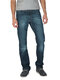

In [17]:
display(dataset[1]["image"])

In [18]:
dataset[1]["image"].save("product_images/product_1.png")

In [21]:
product = {
    "name": dataset[1]["productDisplayName"],
    "image_path": "product_images/product_1.png",
    "category": dataset[1]["masterCategory"],
    "price": 49.99
}

In [22]:
print(product)

{'name': 'Peter England Men Party Blue Jeans', 'image_path': 'product_images/product_1.png', 'category': 'Apparel', 'price': 49.99}


In [23]:
import base64

In [33]:
def encode_image_to_base64(image_path):
    with open(image_path, "rb") as image_file:
        encoded_string = base64.b64encode(image_file.read()).decode("utf-8")
    return encoded_string

In [25]:
encoded_image = encode_image_to_base64(product["image_path"])
print(len(encoded_image))

8044


In [110]:
prompt = f"""Describe this product using the image and these details:
Name: {product_4["name"]}
Category: {product_4["category"]}
Price: ${product_4["price"]}

Do not invent features.


Return only valid JSON with these fields:
- title: a short product title
- description: a product description
- features: a list of product features
- keywords: a list of SEO keywords

Do not claim comfort, durability, or material composition unless provided in the product data.
"""

In [111]:
print(prompt)

Describe this product using the image and these details:
Name: Puma Men Grey T-shirt
Category: Apparel
Price: $189879.99

Do not invent features.


Return only valid JSON with these fields:
- title: a short product title
- description: a product description
- features: a list of product features
- keywords: a list of SEO keywords

Do not claim comfort, durability, or material composition unless provided in the product data.



In [69]:
image_url = f"data:image/png;base64,{encoded_image}"

In [112]:
response = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": image_url}}
            ]
        }
    ]
)

print(response.choices[0].message.content)

```json
{
  "title": "Puma Men Grey T-shirt",
  "description": "Stylish grey t-shirt from Puma, perfect for everyday wear and athletic activities.",
  "features": [
    "Grey color",
    "Short sleeves",
    "Puma logo on the front"
  ],
  "keywords": [
    "Puma",
    "Men's T-shirt",
    "Grey T-shirt",
    "Apparel",
    "Fashion",
    "Casual Wear"
  ]
}
```


In [44]:
print(response.choices[0].message.content)

The Peter England Men Party Blue Jeans are a stylish option in the apparel category, priced at $49.99. These jeans feature a classic blue color with a slightly faded finish, making them suitable for casual or party settings. The design includes a regular fit with a standard button and zip closure. The material appears durable, offering both comfort and a modern look.


In [34]:
response.choices

[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='The product is a pair of blue jeans with a faded, worn effect on the thighs and knees. The jeans have a classic five-pocket design and appear to have a straight or slightly tapered fit.', refusal=None, role='assistant', annotations=[], audio=None, function_call=None, tool_calls=None))]

In [35]:
print(len(response.choices))


1


In [37]:
print(response)

ChatCompletion(id='chatcmpl-EhYFYpKwLVluT8y9egBDRNujHOjF6', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='The product is a pair of blue jeans with a faded, worn effect on the thighs and knees. The jeans have a classic five-pocket design and appear to have a straight or slightly tapered fit.', refusal=None, role='assistant', annotations=[], audio=None, function_call=None, tool_calls=None))], created=1794048468, model='gpt-4o-2024-08-06', object='chat.completion', metadata=None, moderation=None, service_tier='default', system_fingerprint='fp_936db6157f', usage=CompletionUsage(completion_tokens=39, prompt_tokens=273, total_tokens=312, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=0, rejected_prediction_tokens=0, text_tokens=None), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=None, cached_tokens=0, image_tokens=None, text_tokens=None)))


In [49]:
print(response.choices[0].message.content)


```json
{
  "title": "Peter England Men's Party Blue Jeans",
  "description": "Upgrade your wardrobe with these stylish blue jeans from Peter England, perfect for parties and casual outings.",
  "features": [
    "Comfortable fit",
    "Durable fabric",
    "Stylish blue color"
  ],
  "keywords": [
    "Peter England",
    "Men's jeans",
    "Blue jeans",
    "Party wear",
    "Fashion",
    "Casual pants",
    "Stylish denim"
  ]
}
```


In [116]:
import json

text = response.choices[0].message.content
text = text.strip().removeprefix("```json").removesuffix("```").strip()


listing_4 = json.loads(text)

In [115]:
print(listing_2["title"])
print(listing_2["description"])
print(listing_2["features"])

print(listing_3["title"])
print(listing_3["description"]) 
print(listing_3["features"])

print(listing_4["title"])
print(listing_4["description"])
print(listing_4["features"])


Titan Women Silver Watch
A sleek and stylish silver watch designed for women, perfect for both casual and formal occasions.
['Elegant design', 'Silver-tone finish', 'Analog display', 'Slim bracelet style']
Manchester United Men Solid Black Track Pants
Stylish and sleek Manchester United track pants in a classic black design, perfect for fans and casual wear.
['Solid black color', 'Official Manchester United branding']
Puma Men Grey T-shirt
Stylish grey t-shirt from Puma, perfect for everyday wear and athletic activities.
['Grey color', 'Short sleeves', 'Puma logo on the front']


In [97]:
print(listing_3["title"])
print(listing_3["description"])
print(listing_3 ["features"])


Manchester United Men Solid Black Track Pants
Stylish and sleek Manchester United track pants in a classic black design, perfect for fans and casual wear.
['Solid black color', 'Official Manchester United branding']


In [118]:
with open("product_listing_4.json", "w", encoding="utf-8") as file:
    json.dump(listing_4, file, indent=4)

Titan Women Silver Watch


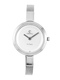

In [64]:
print(dataset[2]["productDisplayName"])
display(dataset[2]["image"])

Manchester United Men Solid Black Track Pants


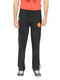

In [99]:
print(dataset[3]["productDisplayName"])
display(dataset[3]["image"])

Manchester United Men Solid Black Track Pants


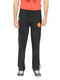

In [81]:
print(dataset[3]["productDisplayName"])
display(dataset[3]["image"])

Puma Men Grey T-shirt


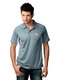

In [109]:
print(dataset[4]["productDisplayName"])
display(dataset[4]["image"])

In [84]:
dataset[2]["image"].save("product_images/product_2.png")
dataset[3]["image"].save("product_images/product_3.png")        
dataset[4]["image"].save("product_images/product_4.png")        

In [66]:
product_2 = {
    "name": dataset[2]["productDisplayName"],
    "image_path": "product_images/product_2.png",
    "category": dataset[2]["masterCategory"],
    "price": 59.99,
    "description": "",
    "features": [],
    "keywords": [], 
}

In [ ]:
product_3 = {
    "name": dataset[3]["productDisplayName"],
    "image_path": "product_images/product_3.png",
    "category": dataset[3]["masterCategory"],
    "price": 9.99,
    "description": "",
    "features": [],
    "keywords": [], 
}

In [90]:
product_4 = {
    "name": dataset[4]["productDisplayName"],
    "image_path": "product_images/product_4.png",
    "category": dataset[4]["masterCategory"],
    "price": 189879.99,
    "description": "",
    "features": [],
    "keywords": [], 
}

In [100]:
print(listing_4)

NameError: name 'listing_4' is not defined

In [101]:
encoded_image = encode_image_to_base64(product_2["image_path"])
encoded_image = encode_image_to_base64(product_3["image_path"])
encoded_image = encode_image_to_base64(product_4["image_path"]) 
image_url = f"data:image/png;base64,{encoded_image}"

In [92]:
print(product_2)
print(product_3)
print(product_4)   

{'name': 'Titan Women Silver Watch', 'image_path': 'product_images/product_2.png', 'category': 'Accessories', 'price': 59.99, 'description': '', 'features': [], 'keywords': []}
{'name': 'Manchester United Men Solid Black Track Pants', 'image_path': 'product_images/product_3.png', 'category': 'Apparel', 'price': 59.99, 'description': '', 'features': [], 'keywords': []}
{'name': 'Puma Men Grey T-shirt', 'image_path': 'product_images/product_4.png', 'category': 'Apparel', 'price': 189879.99, 'description': '', 'features': [], 'keywords': []}


In [ ]:
with open("product_listing_3.json", "w", encoding="utf-8") as file:
    json.dump(listing_3, file, indent=4)
with open("product_listing_4.json", "w", encoding="utf-8") as file:
    json.dump(listing_4, file, indent=4)    
with open("product_listing_2.json", "w", encoding="utf-8") as file:
    json.dump(listing_2, file, indent=4)        

In [29]:
class ProductListing(BaseModel):
    title: str = Field(min_length=1)
    description: str = Field(min_length=1)
    features: list[str]
    keywords: list[str]

In [41]:
import base64

def encode_image_to_base64(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

In [39]:
def generate_listing(product):
    product = ProductInput.model_validate(product).model_dump()
    encoded_image = encode_image_to_base64(product["image_path"])
    image_url = f"data:image/png;base64,{encoded_image}"
    prompt = f"""Describe this product using the image and these details:
Name: {product["name"]}
Category: {product["category"]}
Price: ${product["price"]}

Do not invent features.


Return only valid JSON with these fields:
- title: a short product title
- description: a product description
- features: a list of product features
- keywords: a list of SEO keywords

Do not claim comfort, durability, or material composition unless provided in the product data.
"""
    response = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": image_url}}
            ]
        }
    ]
)
    
    text = response.choices[0].message.content
    text = text.strip().removeprefix("```json").removesuffix("```").strip()
    listing_data = json.loads(text)
    validated_listing = ProductListing.model_validate(listing_data)
    return validated_listing.model_dump()



In [49]:
from openai import OpenAI

client = OpenAI()

In [50]:
listing = generate_listing(product_data)
print(listing)

{'title': 'Puma T-shirt', 'description': 'Stylish Puma T-shirt perfect for casual wear.', 'features': ['Short sleeves', 'Collared design', 'Puma logo on chest'], 'keywords': ['Puma T-shirt', 'casual wear', 'apparel', 'short sleeve shirt', 'collared T-shirt']}


In [28]:
try:
    generate_listing(invalid_data)
except ValidationError as error:
    print("Request stopped:", error)

Request stopped: 1 validation error for ProductInput
price
  Input should be greater than 0 [type=greater_than, input_value=-5, input_type=int]
    For further information visit https://errors.pydantic.dev/2.12/v/greater_than


In [121]:
watch_listing = generate_listing(product_2)
print(watch_listing["title"])

Titan Women Silver Watch


In [129]:
products = [product_2, product_3, product_4]

In [130]:
for product in products:
    print(product["name"])

Titan Women Silver Watch
Manchester United Men Solid Black Track Pants
Puma Men Grey T-shirt


In [131]:
listings = []
for product in products:
    listing = generate_listing(product)
    listings.append(listing)

In [128]:
with open("product_listings.json", "w", encoding="utf-8") as file:
    json.dump(listings, file, indent=4)

In [127]:
print(len(listings))

3


In [132]:
test_product = product_4.copy()
test_product["image_path"] = "product_images/missing.png"

In [133]:
try:
    generate_listing(test_product)
except FileNotFoundError:
    print("Image not found. Check the product's image_path.")

Image not found. Check the product's image_path.


In [52]:
with open("invalid_product.json", "r", encoding="utf-8") as file:
    loaded_data = json.load(file)

try:
    validated_product = ProductInput.model_validate(loaded_data)
    print("Valid product:", validated_product)
except ValidationError as error:
    print("Invalid product:", error)

Invalid product: 1 validation error for ProductInput
price
  Input should be greater than 0 [type=greater_than, input_value=-5, input_type=int]
    For further information visit https://errors.pydantic.dev/2.12/v/greater_than


In [51]:
try:
    ProductListing.model_validate({"title": "Puma T-shirt"})
except ValidationError as error:
    print(error)

3 validation errors for ProductListing
description
  Field required [type=missing, input_value={'title': 'Puma T-shirt'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.12/v/missing
features
  Field required [type=missing, input_value={'title': 'Puma T-shirt'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.12/v/missing
keywords
  Field required [type=missing, input_value={'title': 'Puma T-shirt'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.12/v/missing


In [54]:
requests = [product_data, invalid_data]

In [55]:
for request in requests:
    try:
        product = ProductInput.model_validate(request)
        print("Valid:", product.name)
    except ValidationError:
        print("Invalid product")

Valid: Puma T-shirt
Invalid product


In [56]:
def handle_client_request(payload: dict):
    try:
        listing = generate_listing(payload)
        return {"success": True, "listing": listing, "error": None}
    except ValidationError as error:
        return {"success": False, "listing": None, "error": str(error)}
    except Exception as error:
        return {"success": False, "listing": None, "error": str(error)}

In [57]:
requests = [product_data, invalid_data]

results = [handle_client_request(request) for request in requests]

with open("batch_requests.json", "w", encoding="utf-8") as file:
    json.dump(requests, file, indent=4)

with open("batch_results.json", "w", encoding="utf-8") as file:
    json.dump(results, file, indent=4)

for result in results:
    print("Success:", result["success"])

Success: True
Success: False
